# 04 - Conventional Machine-Learning Feature-Stage Comparison

### 4.1. Objective

Evaluate how progressively adding rhythm and morphology context affects
conventional ECG heartbeat classifiers.

Three model families are evaluated:

1. Logistic Regression
2. Random Forest
3. XGBoost

Each model is evaluated using the same four progressive input stages:

### Stage 1 - ECG
255 standardized ECG waveform samples.

### Stage 2 - ECG + 6RR
255 ECG samples + 6 immediate RR features.

### Stage 3 - ECG + 13Context
255 ECG samples + 6 RR features + 3 rhythm-history features
+ 4 morphology-context features.

### Stage 4 - ECG + 21
255 ECG samples + the complete 21-feature engineered representation.

Therefore, the tabular input dimensions are:

- ECG: 255
- ECG + 6RR: 261
- ECG + 13Context: 268
- ECG + 21: 276

### Experimental Controls

All model and feature-stage comparisons use:

- the same canonical heartbeat rows
- the same N/S/V/F labels
- the same DS1 development records
- the same fixed five DS1 record-grouped cross-validation folds
- the same DS2 evaluation records
- the same metric definitions
- the same class order

Hyperparameters are optimized separately for each model and feature stage
using DS1 only. The same candidate search space is used for all four stages
within a given model family.

Macro-F1 is the primary model-selection metric.
Balanced accuracy is used as the secondary criterion.

### 4.2. Load Canonical Experimental Data

Load the canonical ECG, RR6, Context13, Engineered21, labels, metadata,
and fixed DS1 cross-validation folds generated by Notebooks 02 and 03.

No heartbeat rows, labels, or cross-validation folds are created or
modified in this notebook.

In [4]:
# ============================================================
# SECTION 1: IMPORT LIBRARIES
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    matthews_corrcoef,
)

from xgboost import XGBClassifier


# ============================================================
# SECTION 2: FIND PROJECT ROOT
# ============================================================

CURRENT_DIR = Path.cwd().resolve()

PROJECT_ROOT = CURRENT_DIR


while not (
    PROJECT_ROOT
    / "requirements.txt"
).exists():

    if (
        PROJECT_ROOT.parent
        == PROJECT_ROOT
    ):

        raise FileNotFoundError(
            "Could not locate the ECG-ML project root."
        )

    PROJECT_ROOT = (
        PROJECT_ROOT.parent
    )


# ============================================================
# SECTION 3: DEFINE PROJECT DIRECTORIES
# ============================================================

PROCESSED_DATA_DIR = (
    PROJECT_ROOT
    / "data"
    / "processed"
)

MODELS_DIR = (
    PROJECT_ROOT
    / "models"
)

RESULTS_DIR = (
    PROJECT_ROOT
    / "results"
)

METRICS_DIR = (
    RESULTS_DIR
    / "metrics"
)

FIGURES_DIR = (
    RESULTS_DIR
    / "figures"
)


MODELS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

METRICS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# SECTION 4: DEFINE REQUIRED INPUT FILES
# ============================================================

required_files = {

    "DS1 ECG":
        PROCESSED_DATA_DIR
        / "X_ds1_ecg.npy",

    "DS2 ECG":
        PROCESSED_DATA_DIR
        / "X_ds2_ecg.npy",

    "DS1 RR6":
        PROCESSED_DATA_DIR
        / "X_ds1_rr6.npy",

    "DS2 RR6":
        PROCESSED_DATA_DIR
        / "X_ds2_rr6.npy",

    "DS1 Context13":
        PROCESSED_DATA_DIR
        / "X_ds1_context13.npy",

    "DS2 Context13":
        PROCESSED_DATA_DIR
        / "X_ds2_context13.npy",

    "DS1 Engineered21":
        PROCESSED_DATA_DIR
        / "X_ds1_engineered21.npy",

    "DS2 Engineered21":
        PROCESSED_DATA_DIR
        / "X_ds2_engineered21.npy",

    "DS1 labels":
        PROCESSED_DATA_DIR
        / "y_ds1.npy",

    "DS2 labels":
        PROCESSED_DATA_DIR
        / "y_ds2.npy",

    "DS1 metadata":
        PROCESSED_DATA_DIR
        / "ds1_metadata.csv",

    "DS2 metadata":
        PROCESSED_DATA_DIR
        / "ds2_metadata.csv",

    "Fixed CV folds":
        PROCESSED_DATA_DIR
        / "ds1_cv_record_folds.csv",
}


# ============================================================
# SECTION 5: VERIFY REQUIRED FILES
# ============================================================

for (
    file_label,
    file_path

) in required_files.items():

    if not file_path.exists():

        raise FileNotFoundError(
            f"{file_label} was not found:\n"
            f"{file_path}"
        )


# ============================================================
# SECTION 6: LOAD CANONICAL ECG
# ============================================================

X_ds1_ecg = np.load(
    required_files[
        "DS1 ECG"
    ]
)

X_ds2_ecg = np.load(
    required_files[
        "DS2 ECG"
    ]
)


# ============================================================
# SECTION 7: LOAD RR6
# ============================================================

X_ds1_rr6 = np.load(
    required_files[
        "DS1 RR6"
    ]
)

X_ds2_rr6 = np.load(
    required_files[
        "DS2 RR6"
    ]
)


# ============================================================
# SECTION 8: LOAD CONTEXT13
# ============================================================

X_ds1_context13 = np.load(
    required_files[
        "DS1 Context13"
    ]
)

X_ds2_context13 = np.load(
    required_files[
        "DS2 Context13"
    ]
)


# ============================================================
# SECTION 9: LOAD ENGINEERED21
# ============================================================

X_ds1_engineered21 = np.load(
    required_files[
        "DS1 Engineered21"
    ]
)

X_ds2_engineered21 = np.load(
    required_files[
        "DS2 Engineered21"
    ]
)


# ============================================================
# SECTION 10: LOAD LABELS
# ============================================================

y_ds1 = (
    np.load(
        required_files[
            "DS1 labels"
        ]
    )
    .astype(str)
)

y_ds2 = (
    np.load(
        required_files[
            "DS2 labels"
        ]
    )
    .astype(str)
)


# ============================================================
# SECTION 11: LOAD METADATA
# ============================================================

ds1_metadata = pd.read_csv(
    required_files[
        "DS1 metadata"
    ],
    dtype={
        "beat_uid": str,
        "record_id": str,
    }
)

ds2_metadata = pd.read_csv(
    required_files[
        "DS2 metadata"
    ],
    dtype={
        "beat_uid": str,
        "record_id": str,
    }
)


# ============================================================
# SECTION 12: LOAD FIXED DS1 RECORD FOLDS
# ============================================================

ds1_record_folds = pd.read_csv(
    required_files[
        "Fixed CV folds"
    ],
    dtype={
        "record_id": str,
        "cv_fold": int,
    }
)


# ============================================================
# SECTION 13: DEFINE CLASS ORDER
# ============================================================

CLASS_NAMES = [
    "N",
    "S",
    "V",
    "F",
]


# ============================================================
# SECTION 14: VERIFY CANONICAL ROW ALIGNMENT
# ============================================================

assert (
    len(X_ds1_ecg)
    == len(X_ds1_rr6)
    == len(X_ds1_context13)
    == len(X_ds1_engineered21)
    == len(y_ds1)
    == len(ds1_metadata)
)


assert (
    len(X_ds2_ecg)
    == len(X_ds2_rr6)
    == len(X_ds2_context13)
    == len(X_ds2_engineered21)
    == len(y_ds2)
    == len(ds2_metadata)
)


# ============================================================
# SECTION 15: VERIFY DIMENSIONS
# ============================================================

assert X_ds1_ecg.shape[1] == 255
assert X_ds1_rr6.shape[1] == 6
assert X_ds1_context13.shape[1] == 13
assert X_ds1_engineered21.shape[1] == 21


assert X_ds2_ecg.shape[1] == 255
assert X_ds2_rr6.shape[1] == 6
assert X_ds2_context13.shape[1] == 13
assert X_ds2_engineered21.shape[1] == 21


# ============================================================
# SECTION 16: VERIFY LABEL ALIGNMENT
# ============================================================

assert np.array_equal(
    y_ds1,
    ds1_metadata[
        "class"
    ]
    .astype(str)
    .to_numpy()
)


assert np.array_equal(
    y_ds2,
    ds2_metadata[
        "class"
    ]
    .astype(str)
    .to_numpy()
)


# ============================================================
# SECTION 17: VERIFY UNIQUE HEARTBEAT IDS
# ============================================================

assert (
    ds1_metadata[
        "beat_uid"
    ]
    .is_unique
)

assert (
    ds2_metadata[
        "beat_uid"
    ]
    .is_unique
)


# ============================================================
# SECTION 18: DISPLAY DATA SUMMARY
# ============================================================

print("=" * 80)
print("CANONICAL MODEL DATA")
print("=" * 80)

print(
    "DS1 ECG:",
    X_ds1_ecg.shape
)

print(
    "DS1 RR6:",
    X_ds1_rr6.shape
)

print(
    "DS1 Context13:",
    X_ds1_context13.shape
)

print(
    "DS1 Engineered21:",
    X_ds1_engineered21.shape
)


print(
    "\nDS2 ECG:",
    X_ds2_ecg.shape
)

print(
    "DS2 RR6:",
    X_ds2_rr6.shape
)

print(
    "DS2 Context13:",
    X_ds2_context13.shape
)

print(
    "DS2 Engineered21:",
    X_ds2_engineered21.shape
)

print("=" * 80)

CANONICAL MODEL DATA
DS1 ECG: (50992, 255)
DS1 RR6: (50992, 6)
DS1 Context13: (50992, 13)
DS1 Engineered21: (50992, 21)

DS2 ECG: (49686, 255)
DS2 RR6: (49686, 6)
DS2 Context13: (49686, 13)
DS2 Engineered21: (49686, 21)


### 4.3. Common Experimental Setup

Before fitting individual classifiers, construct the four input stages and
load the exact fixed cross-validation folds created in Notebook 02.

No new cross-validation split is generated in this notebook.

In [5]:
# ============================================================
# CELL 1: COMMON FOUR-STAGE EXPERIMENT SETUP
# ============================================================

import numpy as np
import pandas as pd


# ============================================================
# SECTION 1: OUTPUT DIRECTORY ALIASES
# ============================================================

RESULTS_METRICS_DIR = (
    METRICS_DIR
)

RESULTS_FIGURES_DIR = (
    FIGURES_DIR
)


# ============================================================
# SECTION 2: DEFINE FOUR EXPERIMENTAL STAGES
# ============================================================

STAGE_NAMES = [
    "ECG",
    "ECG+6RR",
    "ECG+13Context",
    "ECG+21",
]


# ============================================================
# SECTION 3: CONSTRUCT TABULAR INPUTS
# ============================================================

stage_data = {

    "ECG": {
        "X_ds1":
            X_ds1_ecg,

        "X_ds2":
            X_ds2_ecg,

        "n_features":
            255,
    },


    "ECG+6RR": {
        "X_ds1":
            np.column_stack(
                [
                    X_ds1_ecg,
                    X_ds1_rr6,
                ]
            ).astype(
                np.float32
            ),

        "X_ds2":
            np.column_stack(
                [
                    X_ds2_ecg,
                    X_ds2_rr6,
                ]
            ).astype(
                np.float32
            ),

        "n_features":
            261,
    },


    "ECG+13Context": {
        "X_ds1":
            np.column_stack(
                [
                    X_ds1_ecg,
                    X_ds1_context13,
                ]
            ).astype(
                np.float32
            ),

        "X_ds2":
            np.column_stack(
                [
                    X_ds2_ecg,
                    X_ds2_context13,
                ]
            ).astype(
                np.float32
            ),

        "n_features":
            268,
    },


    "ECG+21": {
        "X_ds1":
            np.column_stack(
                [
                    X_ds1_ecg,
                    X_ds1_engineered21,
                ]
            ).astype(
                np.float32
            ),

        "X_ds2":
            np.column_stack(
                [
                    X_ds2_ecg,
                    X_ds2_engineered21,
                ]
            ).astype(
                np.float32
            ),

        "n_features":
            276,
    },
}


# ============================================================
# SECTION 4: VERIFY STAGE DIMENSIONS
# ============================================================

for stage_name in STAGE_NAMES:

    stage = (
        stage_data[
            stage_name
        ]
    )

    assert (
        stage[
            "X_ds1"
        ].shape
        ==
        (
            len(y_ds1),
            stage[
                "n_features"
            ],
        )
    )


    assert (
        stage[
            "X_ds2"
        ].shape
        ==
        (
            len(y_ds2),
            stage[
                "n_features"
            ],
        )
    )


# ============================================================
# SECTION 5: DEFINE RECORD GROUPS
# ============================================================

ds1_groups = (
    ds1_metadata[
        "record_id"
    ]
    .astype(str)
    .to_numpy()
)


# ============================================================
# SECTION 6: VERIFY FIXED FOLD FILE
# ============================================================

assert (
    ds1_record_folds[
        "record_id"
    ]
    .is_unique
)


assert (
    len(
        ds1_record_folds
    )
    == 22
)


fold_map = dict(
    zip(
        ds1_record_folds[
            "record_id"
        ],

        ds1_record_folds[
            "cv_fold"
        ]
    )
)


# ============================================================
# SECTION 7: MAP EVERY DS1 BEAT TO ITS FIXED FOLD
# ============================================================

sample_folds = (
    ds1_metadata[
        "record_id"
    ]
    .map(
        fold_map
    )
)


assert (
    sample_folds
    .notna()
    .all()
)


sample_folds = (
    sample_folds
    .to_numpy(
        dtype=int
    )
)


# ============================================================
# SECTION 8: VERIFY AGAINST SAVED METADATA FOLD COLUMN
# ============================================================

assert np.array_equal(
    sample_folds,

    ds1_metadata[
        "cv_fold"
    ]
    .to_numpy(
        dtype=int
    )
)


# ============================================================
# SECTION 9: CREATE FIXED TRAIN / VALIDATION INDEX LIST
# ============================================================

N_SPLITS = 5

cv_folds = []


for fold_number in range(
    1,
    N_SPLITS + 1
):

    train_idx = np.where(
        sample_folds
        != fold_number
    )[0]


    val_idx = np.where(
        sample_folds
        == fold_number
    )[0]


    cv_folds.append(
        (
            train_idx,
            val_idx,
        )
    )


# ============================================================
# SECTION 10: VERIFY FOLDS
# ============================================================

for fold_number, (
    train_idx,
    val_idx

) in enumerate(
    cv_folds,
    start=1
):

    train_records = set(
        ds1_groups[
            train_idx
        ]
    )


    val_records = set(
        ds1_groups[
            val_idx
        ]
    )


    assert (
        train_records
        .isdisjoint(
            val_records
        )
    )


    y_val = (
        y_ds1[
            val_idx
        ]
    )


    for class_name in CLASS_NAMES:

        assert np.sum(
            y_val
            == class_name
        ) > 0


# ============================================================
# SECTION 11: DISPLAY FINAL STAGE SETUP
# ============================================================

stage_summary = pd.DataFrame(
    [
        {
            "stage":
                stage_name,

            "n_features":
                stage_data[
                    stage_name
                ][
                    "n_features"
                ],
        }

        for stage_name
        in STAGE_NAMES
    ]
)


display(
    stage_summary
)


print(
    "Fixed DS1 folds loaded successfully."
)

print(
    "No CV folds were generated in Notebook 04."
)

,stage,n_features
0,ECG,255
1,ECG+6RR,261
2,ECG+13Context,268
3,ECG+21,276


Fixed DS1 folds loaded successfully.
No CV folds were generated in Notebook 04.


In [6]:
# ============================================================
# RESTORE SAVED MODELS AND CV RESULTS WITHOUT RETRAINING
# ============================================================

import pandas as pd
import joblib


def select_best_cv_row(results_df):
    return (
        results_df.sort_values(
            by=[
                "mean_cv_macro_f1",
                "mean_cv_balanced_accuracy",
            ],
            ascending=[False, False],
            kind="stable",
        )
        .iloc[0]
    )


# Load DS1 cross-validation results.
logistic_cv_results_df = pd.read_csv(
    RESULTS_METRICS_DIR / "logistic_four_stage_cv.csv"
)

rf_cv_results_df = pd.read_csv(
    RESULTS_METRICS_DIR / "random_forest_four_stage_cv.csv"
)

xgb_cv_results_df = pd.read_csv(
    RESULTS_METRICS_DIR / "xgboost_four_stage_cv.csv"
)


# Restore the best configuration for each stage using DS1 only.
def restore_best_per_stage(cv_results):
    return pd.DataFrame([
        select_best_cv_row(
            cv_results.loc[cv_results["stage"] == stage]
        )
        for stage in STAGE_NAMES
    ]).reset_index(drop=True)


best_logistic_df = restore_best_per_stage(logistic_cv_results_df)
best_rf_df = restore_best_per_stage(rf_cv_results_df)
best_xgb_df = restore_best_per_stage(xgb_cv_results_df)


# Load the previously trained models.
artifact_dir = MODELS_DIR / "conventional_four_stage"

logistic_models = {}
rf_models = {}
xgb_models = {}

for stage in STAGE_NAMES:
    safe_stage = stage.replace("+", "_plus_")

    lr_artifact = joblib.load(
        artifact_dir / f"logistic_{safe_stage}.joblib"
    )
    logistic_models[stage] = lr_artifact["model"]

    rf_artifact = joblib.load(
        artifact_dir / f"random_forest_{safe_stage}.joblib"
    )
    rf_models[stage] = rf_artifact["model"]

    xgb_artifact = joblib.load(
        artifact_dir / f"xgboost_{safe_stage}.joblib"
    )
    xgb_models[stage] = xgb_artifact

# Restore XGBoost's numeric-label mapping.
INT_TO_CLASS = xgb_artifact["int_to_class"]

print("Saved models and CV results loaded. No retraining performed.")

Saved models and CV results loaded. No retraining performed.


In [3]:
# ============================================================
# CELL 2: COMMON METRIC FUNCTIONS
# ============================================================

def calculate_metrics(
    y_true,
    y_pred
):
    """
    Calculate the common evaluation metrics used
    across every model and feature stage.
    """

    return {

        "accuracy":
            accuracy_score(
                y_true,
                y_pred
            ),

        "balanced_accuracy":
            balanced_accuracy_score(
                y_true,
                y_pred
            ),

        "macro_precision":
            precision_score(
                y_true,
                y_pred,
                labels=CLASS_NAMES,
                average="macro",
                zero_division=0,
            ),

        "macro_recall":
            recall_score(
                y_true,
                y_pred,
                labels=CLASS_NAMES,
                average="macro",
                zero_division=0,
            ),

        "macro_f1":
            f1_score(
                y_true,
                y_pred,
                labels=CLASS_NAMES,
                average="macro",
                zero_division=0,
            ),

        "weighted_f1":
            f1_score(
                y_true,
                y_pred,
                labels=CLASS_NAMES,
                average="weighted",
                zero_division=0,
            ),

        "mcc":
            matthews_corrcoef(
                y_true,
                y_pred
            ),
    }


def select_best_cv_row(
    results_df
):
    """
    Select the best hyperparameter configuration.

    Primary:
        Mean CV Macro-F1

    Secondary:
        Mean CV Balanced Accuracy
    """

    return (
        results_df
        .sort_values(
            by=[
                "mean_cv_macro_f1",
                "mean_cv_balanced_accuracy",
            ],
            ascending=[
                False,
                False,
            ],
        )
        .iloc[0]
    )

### Addition for confusion matrix

In [7]:
# ============================================================
# SHARED FUNCTION: DS2 CONFUSION MATRICES
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay


def plot_ds2_confusion(y_pred, model_name, stage_name, filename):
    labels = ["N", "S", "V", "F"]

    cm = confusion_matrix(
        y_ds2,
        y_pred,
        labels=labels,
    )

    # Each row shows percentages within one true class.
    row_totals = cm.sum(axis=1, keepdims=True)
    cm_percent = np.divide(
        cm.astype(float),
        row_totals,
        out=np.zeros_like(cm, dtype=float),
        where=row_totals != 0,
    ) * 100

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.8))

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=labels,
    ).plot(
        ax=axes[0],
        cmap="Blues",
        values_format="d",
        colorbar=False,
    )
    axes[0].set_title("Number of beats")

    ConfusionMatrixDisplay(
        confusion_matrix=cm_percent,
        display_labels=labels,
    ).plot(
        ax=axes[1],
        cmap="Blues",
        values_format=".1f",
        colorbar=False,
        im_kw={"vmin": 0, "vmax": 100},
    )
    axes[1].set_title("Percentage within each true class (%)")

    fig.suptitle(f"{model_name} | {stage_name} | DS2")
    fig.tight_layout()

    RESULTS_FIGURES_DIR.mkdir(parents=True, exist_ok=True)
    RESULTS_METRICS_DIR.mkdir(parents=True, exist_ok=True)

    fig.savefig(
        RESULTS_FIGURES_DIR / f"{filename}.png",
        dpi=300,
        bbox_inches="tight",
    )
    fig.savefig(
        RESULTS_FIGURES_DIR / f"{filename}.pdf",
        bbox_inches="tight",
    )

    cm_table = pd.DataFrame(
        cm,
        index=pd.Index(labels, name="True class"),
        columns=pd.Index(labels, name="Predicted class"),
    )
    cm_table.to_csv(RESULTS_METRICS_DIR / f"{filename}.csv")

    plt.show()
    plt.close(fig)

    print(f"DS1-selected stage: {stage_name}")
    print(f"DS2 beats evaluated: {cm.sum():,}")

    return cm_table

In [4]:
# ============================================================
# CELL 3: LOGISTIC REGRESSION
#         FOUR-STAGE FIXED-FOLD CROSS-VALIDATION
# ============================================================

C_GRID = [
    0.01,
    0.10,
    1.00,
    10.00,
]


logistic_cv_rows = []


# ============================================================
# LOOP THROUGH FOUR FEATURE STAGES
# ============================================================

for stage_name in STAGE_NAMES:

    print(
        "\n"
        + "=" * 80
    )

    print(
        f"LOGISTIC REGRESSION | {stage_name}"
    )

    print(
        "=" * 80
    )


    X_stage = (
        stage_data[
            stage_name
        ][
            "X_ds1"
        ]
    )


    # ========================================================
    # TEST EACH C VALUE
    # ========================================================

    for C_value in C_GRID:

        fold_macro_f1 = []

        fold_balanced_accuracy = []


        for fold_number, (
            train_idx,
            val_idx

        ) in enumerate(
            cv_folds,
            start=1
        ):

            X_train_fold = (
                X_stage[
                    train_idx
                ]
            )

            X_val_fold = (
                X_stage[
                    val_idx
                ]
            )


            y_train_fold = (
                y_ds1[
                    train_idx
                ]
            )

            y_val_fold = (
                y_ds1[
                    val_idx
                ]
            )


            # =================================================
            # FOLD-SPECIFIC PREPROCESSING
            # =================================================

            model = Pipeline(
                [
                    (
                        "imputer",

                        SimpleImputer(
                            strategy="median"
                        )
                    ),

                    (
                        "scaler",

                        StandardScaler()
                    ),

                    (
                        "classifier",

                        LogisticRegression(
                            C=C_value,
                            max_iter=3000,
                            class_weight="balanced",
                            solver="lbfgs",
                            random_state=42,
                        )
                    ),
                ]
            )


            model.fit(
                X_train_fold,
                y_train_fold
            )


            predictions = (
                model.predict(
                    X_val_fold
                )
            )


            metrics = calculate_metrics(
                y_val_fold,
                predictions
            )


            fold_macro_f1.append(
                metrics[
                    "macro_f1"
                ]
            )


            fold_balanced_accuracy.append(
                metrics[
                    "balanced_accuracy"
                ]
            )


        # ====================================================
        # SAVE CV SUMMARY
        # ====================================================

        logistic_cv_rows.append(
            {
                "model":
                    "Logistic Regression",

                "stage":
                    stage_name,

                "C":
                    C_value,

                "mean_cv_macro_f1":
                    float(
                        np.mean(
                            fold_macro_f1
                        )
                    ),

                "std_cv_macro_f1":
                    float(
                        np.std(
                            fold_macro_f1
                        )
                    ),

                "mean_cv_balanced_accuracy":
                    float(
                        np.mean(
                            fold_balanced_accuracy
                        )
                    ),

                "std_cv_balanced_accuracy":
                    float(
                        np.std(
                            fold_balanced_accuracy
                        )
                    ),
            }
        )


# ============================================================
# BUILD COMPLETE LOGISTIC CV TABLE
# ============================================================

logistic_cv_results_df = pd.DataFrame(
    logistic_cv_rows
)


# ============================================================
# SELECT BEST C SEPARATELY FOR EACH STAGE
# ============================================================

best_logistic_rows = []


for stage_name in STAGE_NAMES:

    stage_results = (
        logistic_cv_results_df[
            logistic_cv_results_df[
                "stage"
            ]
            == stage_name
        ]
    )


    best_row = (
        select_best_cv_row(
            stage_results
        )
    )


    best_logistic_rows.append(
        best_row
    )


best_logistic_df = pd.DataFrame(
    best_logistic_rows
).reset_index(
    drop=True
)


display(
    best_logistic_df
)


# ============================================================
# SAVE LOGISTIC CV RESULTS
# ============================================================

logistic_cv_results_df.to_csv(
    RESULTS_METRICS_DIR
    / "logistic_four_stage_cv.csv",
    index=False
)


LOGISTIC REGRESSION | ECG

LOGISTIC REGRESSION | ECG+6RR

LOGISTIC REGRESSION | ECG+13Context

LOGISTIC REGRESSION | ECG+21


,model,stage,C,mean_cv_macro_f1,std_cv_macro_f1,mean_cv_balanced_accuracy,std_cv_balanced_accuracy
0,Logistic Regression,ECG,0.01,0.276867,0.088742,0.401851,0.123100
1,Logistic Regression,ECG+6RR,0.01,0.316991,0.087237,0.452632,0.147960
2,Logistic Regression,ECG+13Context,1.00,0.380601,0.060823,0.570105,0.126372
3,Logistic Regression,ECG+21,0.10,0.402186,0.081380,0.606146,0.143378


In [6]:
# ============================================================
# CELL 4: FINAL LOGISTIC REGRESSION MODELS
#         AND DS2 EVALUATION
# ============================================================

logistic_models = {}

logistic_result_rows = []


for stage_name in STAGE_NAMES:

    # ========================================================
    # GET SELECTED C
    # ========================================================

    best_row = (
        best_logistic_df[
            best_logistic_df[
                "stage"
            ]
            == stage_name
        ]
        .iloc[0]
    )


    best_C = float(
        best_row[
            "C"
        ]
    )


    X_ds1_stage = (
        stage_data[
            stage_name
        ][
            "X_ds1"
        ]
    )


    X_ds2_stage = (
        stage_data[
            stage_name
        ][
            "X_ds2"
        ]
    )


    # ========================================================
    # FINAL PIPELINE
    # ========================================================

    model = Pipeline(
        [
            (
                "imputer",

                SimpleImputer(
                    strategy="median"
                )
            ),

            (
                "scaler",

                StandardScaler()
            ),

            (
                "classifier",

                LogisticRegression(
                    C=best_C,
                    max_iter=3000,
                    class_weight="balanced",
                    solver="lbfgs",
                    random_state=42,
                )
            ),
        ]
    )


    # ========================================================
    # TRAIN ON ALL DS1
    # ========================================================

    model.fit(
        X_ds1_stage,
        y_ds1
    )


    # ========================================================
    # PREDICT DS2
    # ========================================================

    predictions = (
        model.predict(
            X_ds2_stage
        )
    )


    # ========================================================
    # CALCULATE METRICS
    # ========================================================

    metrics = calculate_metrics(
        y_ds2,
        predictions
    )


    logistic_result_rows.append(
        {
            "model":
                "Logistic Regression",

            "stage":
                stage_name,

            "n_features":
                stage_data[
                    stage_name
                ][
                    "n_features"
                ],

            "selected_C":
                best_C,

            "cv_macro_f1_mean":
                best_row[
                    "mean_cv_macro_f1"
                ],

            "cv_macro_f1_std":
                best_row[
                    "std_cv_macro_f1"
                ],

            **metrics,
        }
    )


    logistic_models[
        stage_name
    ] = model


logistic_results_df = pd.DataFrame(
    logistic_result_rows
)


display(
    logistic_results_df
)


logistic_results_df.to_csv(
    RESULTS_METRICS_DIR
    / "logistic_four_stage_ds2.csv",
    index=False
)

,model,stage,n_features,selected_C,cv_macro_f1_mean,cv_macro_f1_std,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mcc
0,Logistic Regression,ECG,255,0.01,0.276867,0.088742,0.596848,0.443638,0.331071,0.443638,0.315228,0.692743,0.166344
1,Logistic Regression,ECG+6RR,261,0.01,0.316991,0.087237,0.701103,0.567614,0.405680,0.567614,0.406439,0.778800,0.308112
2,Logistic Regression,ECG+13Context,268,1.00,0.380601,0.060823,0.767379,0.602094,0.432857,0.602094,0.450327,0.821803,0.364395
3,Logistic Regression,ECG+21,276,0.10,0.402186,0.081380,0.836232,0.572270,0.475225,0.572270,0.491643,0.869018,0.436640


## Confusion Matrix - 'Logistic Regression'

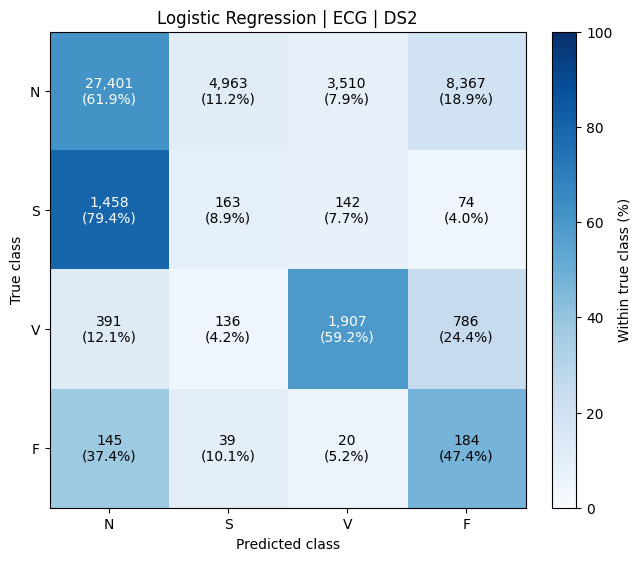

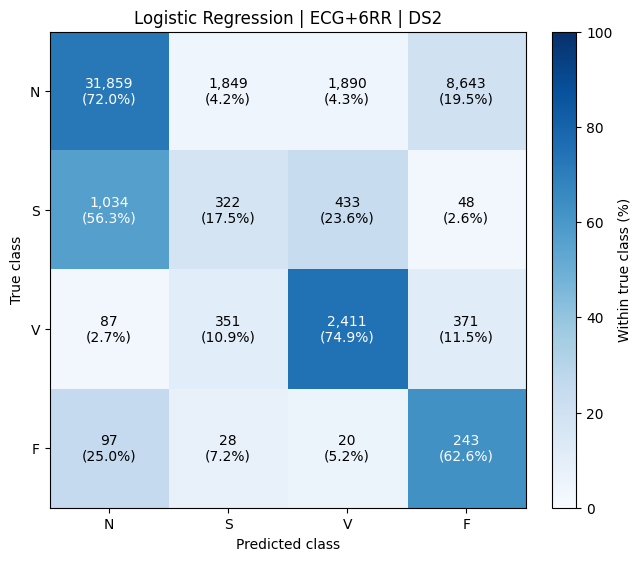

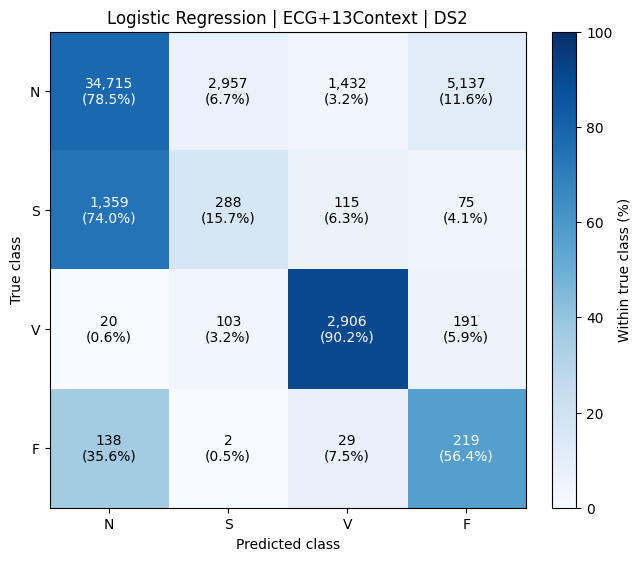

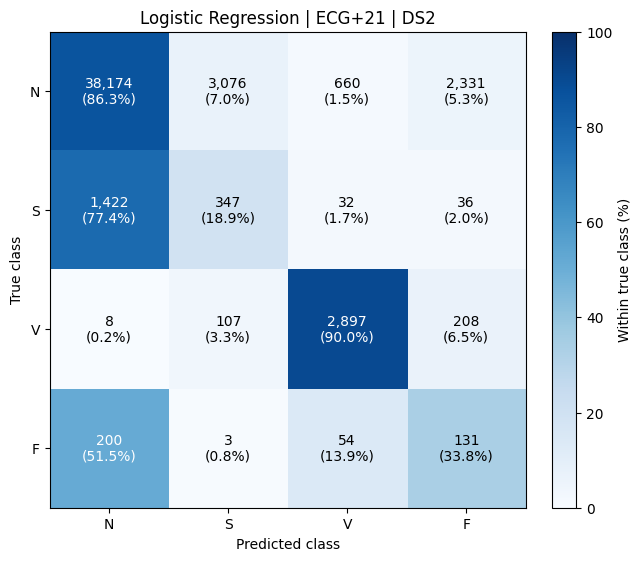

,model,stage,class,precision,recall,f1,support
0,Logistic Regression,ECG,N,0.932165,0.619358,0.744228,44241
1,Logistic Regression,ECG,S,0.030749,0.088732,0.045671,1837
2,Logistic Regression,ECG,V,0.341818,0.592236,0.433458,3220
3,Logistic Regression,ECG,F,0.019552,0.474227,0.037555,388
4,Logistic Regression,ECG+6RR,N,0.963177,0.720124,0.824103,44241
5,Logistic Regression,ECG+6RR,S,0.126275,0.175286,0.146797,1837
6,Logistic Regression,ECG+6RR,V,0.507152,0.748758,0.604715,3220
7,Logistic Regression,ECG+6RR,F,0.026115,0.626289,0.050139,388
8,Logistic Regression,ECG+13Context,N,0.958131,0.784679,0.862774,44241
9,Logistic Regression,ECG+13Context,S,0.085970,0.156777,0.111047,1837


Logistic Regression: four figures and results table saved.


In [12]:
# ============================================================
# LOGISTIC REGRESSION
# ONE CONFUSION-MATRIX FIGURE PER STAGE + RESULTS TABLE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, classification_report
from IPython.display import display

labels = ["N", "S", "V", "F"]
stages = ["ECG", "ECG+6RR", "ECG+13Context", "ECG+21"]

RESULTS_FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_METRICS_DIR.mkdir(parents=True, exist_ok=True)

lr_rows = []
lr_confusion_matrices = {}

for stage in stages:

    # Predict using the trained pipeline.
    predictions = logistic_models[stage].predict(
        stage_data[stage]["X_ds2"]
    )

    cm = confusion_matrix(
        y_ds2, predictions, labels=labels
    )

    # Percentages are calculated within each true-class row.
    row_totals = cm.sum(axis=1, keepdims=True)

    percentages = np.divide(
        cm.astype(float),
        row_totals,
        out=np.zeros_like(cm, dtype=float),
        where=row_totals != 0,
    ) * 100

    # Create one separate figure for this stage.
    fig, ax = plt.subplots(
        figsize=(6.5, 5.5), constrained_layout=True
    )

    im = ax.imshow(
        percentages, cmap="Blues", vmin=0, vmax=100
    )

    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(
                j,
                i,
                f"{cm[i, j]:,}\n({percentages[i, j]:.1f}%)",
                ha="center",
                va="center",
                fontsize=10,
                color=(
                    "white" if percentages[i, j] > 50
                    else "black"
                ),
            )

    ax.set(
        xticks=range(len(labels)),
        yticks=range(len(labels)),
        xticklabels=labels,
        yticklabels=labels,
        xlabel="Predicted class",
        ylabel="True class",
        title=f"Logistic Regression | {stage} | DS2",
    )

    fig.colorbar(
        im, ax=ax, label="Within true class (%)"
    )

    safe_stage = stage.replace("+", "_plus_")
    filename = f"logistic_{safe_stage}_ds2_confusion"

    for extension in ["png", "pdf"]:
        fig.savefig(
            RESULTS_FIGURES_DIR / f"{filename}.{extension}",
            dpi=300,
            bbox_inches="tight",
        )

    plt.show()
    plt.close(fig)

    # Store and save the confusion-matrix counts.
    cm_table = pd.DataFrame(
        cm,
        index=pd.Index(labels, name="True class"),
        columns=pd.Index(labels, name="Predicted class"),
    )

    lr_confusion_matrices[stage] = cm_table
    cm_table.to_csv(
        RESULTS_METRICS_DIR / f"{filename}.csv"
    )

    # Collect per-class results for this stage.
    report = classification_report(
        y_ds2,
        predictions,
        labels=labels,
        output_dict=True,
        zero_division=0,
    )

    for label in labels:
        lr_rows.append({
            "model": "Logistic Regression",
            "stage": stage,
            "class": label,
            "precision": report[label]["precision"],
            "recall": report[label]["recall"],
            "f1": report[label]["f1-score"],
            "support": int(report[label]["support"]),
        })

# Display one table containing all four stages.
logistic_per_class_df = pd.DataFrame(lr_rows)

display(
    logistic_per_class_df.style.format({
        "precision": "{:.6f}",
        "recall": "{:.6f}",
        "f1": "{:.6f}",
        "support": "{:d}",
    })
)

logistic_per_class_df.to_csv(
    RESULTS_METRICS_DIR / "logistic_four_stage_per_class_ds2.csv",
    index=False,
)

print("Logistic Regression: four figures and results table saved.")

### 4.4. Random Forest

Evaluate the same four feature stages with Random Forest using the exact
same fixed DS1 cross-validation folds.

In [11]:
# ============================================================
# RANDOM FOREST HYPERPARAMETER GRID
# ============================================================

RF_PARAMETER_GRID = [

    {
        "max_depth": None,
        "min_samples_leaf": 1,
    },

    {
        "max_depth": None,
        "min_samples_leaf": 2,
    },

    {
        "max_depth": 10,
        "min_samples_leaf": 1,
    },

    {
        "max_depth": 10,
        "min_samples_leaf": 2,
    },

    {
        "max_depth": 20,
        "min_samples_leaf": 1,
    },

    {
        "max_depth": 20,
        "min_samples_leaf": 2,
    },
]


print(
    "RF configurations:",
    len(
        RF_PARAMETER_GRID
    )
)

print(
    "Feature stages:",
    len(
        STAGE_NAMES
    )
)

print(
    "Fixed CV folds:",
    len(
        cv_folds
    )
)

print(
    "Total RF CV fits:",
    len(RF_PARAMETER_GRID)
    * len(STAGE_NAMES)
    * len(cv_folds)
)

RF configurations: 6
Feature stages: 4
Fixed CV folds: 5
Total RF CV fits: 120


In [12]:
# ============================================================
# RANDOM FOREST FOUR-STAGE FIXED-FOLD CV
# ============================================================

rf_cv_rows = []


for stage_name in STAGE_NAMES:

    print(
        "\n"
        + "=" * 80
    )

    print(
        f"RANDOM FOREST | {stage_name}"
    )

    print(
        "=" * 80
    )


    X_stage = (
        stage_data[
            stage_name
        ][
            "X_ds1"
        ]
    )


    for params in RF_PARAMETER_GRID:

        fold_macro_f1 = []

        fold_balanced_accuracy = []


        for (
            train_idx,
            val_idx

        ) in cv_folds:

            model = Pipeline(
                [
                    (
                        "imputer",

                        SimpleImputer(
                            strategy="median"
                        )
                    ),

                    (
                        "classifier",

                        RandomForestClassifier(
                            n_estimators=300,

                            max_depth=
                                params[
                                    "max_depth"
                                ],

                            min_samples_leaf=
                                params[
                                    "min_samples_leaf"
                                ],

                            class_weight=
                                "balanced_subsample",

                            random_state=42,

                            n_jobs=-1,
                        )
                    ),
                ]
            )


            model.fit(
                X_stage[
                    train_idx
                ],

                y_ds1[
                    train_idx
                ],
            )


            predictions = (
                model.predict(
                    X_stage[
                        val_idx
                    ]
                )
            )


            metrics = calculate_metrics(
                y_ds1[
                    val_idx
                ],
                predictions
            )


            fold_macro_f1.append(
                metrics[
                    "macro_f1"
                ]
            )


            fold_balanced_accuracy.append(
                metrics[
                    "balanced_accuracy"
                ]
            )


        rf_cv_rows.append(
            {
                "model":
                    "Random Forest",

                "stage":
                    stage_name,

                "n_estimators":
                    300,

                "max_depth":
                    params[
                        "max_depth"
                    ],

                "min_samples_leaf":
                    params[
                        "min_samples_leaf"
                    ],

                "mean_cv_macro_f1":
                    float(
                        np.mean(
                            fold_macro_f1
                        )
                    ),

                "std_cv_macro_f1":
                    float(
                        np.std(
                            fold_macro_f1
                        )
                    ),

                "mean_cv_balanced_accuracy":
                    float(
                        np.mean(
                            fold_balanced_accuracy
                        )
                    ),

                "std_cv_balanced_accuracy":
                    float(
                        np.std(
                            fold_balanced_accuracy
                        )
                    ),
            }
        )


rf_cv_results_df = pd.DataFrame(
    rf_cv_rows
)


# ============================================================
# SELECT BEST RF CONFIGURATION FOR EACH STAGE
# ============================================================

best_rf_rows = []


for stage_name in STAGE_NAMES:

    stage_results = (
        rf_cv_results_df[
            rf_cv_results_df[
                "stage"
            ]
            == stage_name
        ]
    )


    best_row = (
        select_best_cv_row(
            stage_results
        )
    )


    best_rf_rows.append(
        best_row
    )


best_rf_df = pd.DataFrame(
    best_rf_rows
).reset_index(
    drop=True
)


display(
    best_rf_df
)


rf_cv_results_df.to_csv(
    RESULTS_METRICS_DIR
    / "random_forest_four_stage_cv.csv",
    index=False
)


RANDOM FOREST | ECG

RANDOM FOREST | ECG+6RR

RANDOM FOREST | ECG+13Context

RANDOM FOREST | ECG+21


,model,stage,n_estimators,max_depth,min_samples_leaf,mean_cv_macro_f1,std_cv_macro_f1,mean_cv_balanced_accuracy,std_cv_balanced_accuracy
0,Random Forest,ECG,300,10.0,1,0.379586,0.061815,0.446926,0.063981
1,Random Forest,ECG+6RR,300,NaN,1,0.418121,0.085575,0.431851,0.071927
2,Random Forest,ECG+13Context,300,10.0,2,0.433817,0.050193,0.493087,0.033117
3,Random Forest,ECG+21,300,10.0,2,0.443639,0.055569,0.499214,0.043340


In [13]:
# ============================================================
# FINAL RANDOM FOREST MODELS AND DS2 EVALUATION
# ============================================================

rf_models = {}

rf_result_rows = []


for stage_name in STAGE_NAMES:

    best_row = (
        best_rf_df[
            best_rf_df[
                "stage"
            ]
            == stage_name
        ]
        .iloc[0]
    )


    max_depth = (
        best_row[
            "max_depth"
        ]
    )


    # CSV/DataFrame may represent None as NaN
    if pd.isna(
        max_depth
    ):

        max_depth = None

    else:

        max_depth = int(
            max_depth
        )


    min_samples_leaf = int(
        best_row[
            "min_samples_leaf"
        ]
    )


    model = Pipeline(
        [
            (
                "imputer",

                SimpleImputer(
                    strategy="median"
                )
            ),

            (
                "classifier",

                RandomForestClassifier(
                    n_estimators=300,
                    max_depth=max_depth,
                    min_samples_leaf=min_samples_leaf,
                    class_weight="balanced_subsample",
                    random_state=42,
                    n_jobs=-1,
                )
            ),
        ]
    )


    X_ds1_stage = (
        stage_data[
            stage_name
        ][
            "X_ds1"
        ]
    )


    X_ds2_stage = (
        stage_data[
            stage_name
        ][
            "X_ds2"
        ]
    )


    model.fit(
        X_ds1_stage,
        y_ds1
    )


    predictions = (
        model.predict(
            X_ds2_stage
        )
    )


    metrics = calculate_metrics(
        y_ds2,
        predictions
    )


    rf_result_rows.append(
        {
            "model":
                "Random Forest",

            "stage":
                stage_name,

            "n_features":
                stage_data[
                    stage_name
                ][
                    "n_features"
                ],

            "selected_max_depth":
                max_depth,

            "selected_min_samples_leaf":
                min_samples_leaf,

            "cv_macro_f1_mean":
                best_row[
                    "mean_cv_macro_f1"
                ],

            "cv_macro_f1_std":
                best_row[
                    "std_cv_macro_f1"
                ],

            **metrics,
        }
    )


    rf_models[
        stage_name
    ] = model


rf_results_df = pd.DataFrame(
    rf_result_rows
)


display(
    rf_results_df
)


rf_results_df.to_csv(
    RESULTS_METRICS_DIR
    / "random_forest_four_stage_ds2.csv",
    index=False
)

,model,stage,n_features,selected_max_depth,selected_min_samples_leaf,cv_macro_f1_mean,cv_macro_f1_std,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mcc
0,Random Forest,ECG,255,10.0,1,0.379586,0.061815,0.901200,0.452044,0.449002,0.452044,0.450487,0.897787,0.495365
1,Random Forest,ECG+6RR,261,NaN,1,0.418121,0.085575,0.944532,0.463964,0.675577,0.463964,0.475130,0.923356,0.687283
2,Random Forest,ECG+13Context,268,10.0,2,0.433817,0.050193,0.942922,0.509812,0.581920,0.509812,0.516084,0.928858,0.686147
3,Random Forest,ECG+21,276,10.0,2,0.443639,0.055569,0.942700,0.500303,0.577558,0.500303,0.508275,0.927720,0.681922


## Confusion matrix random forest

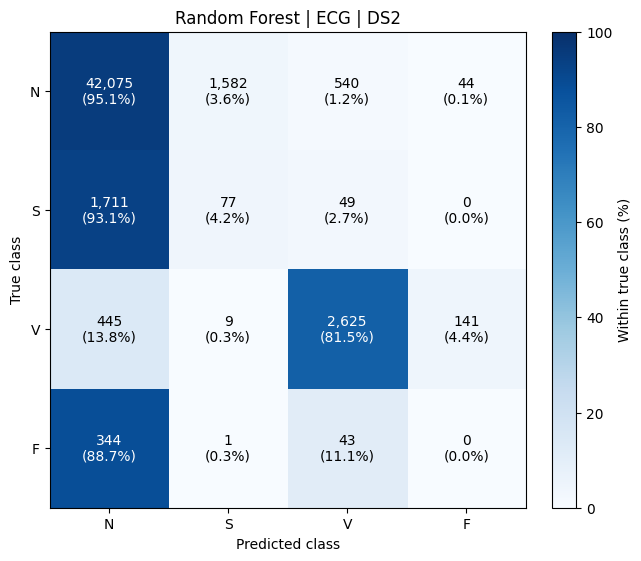

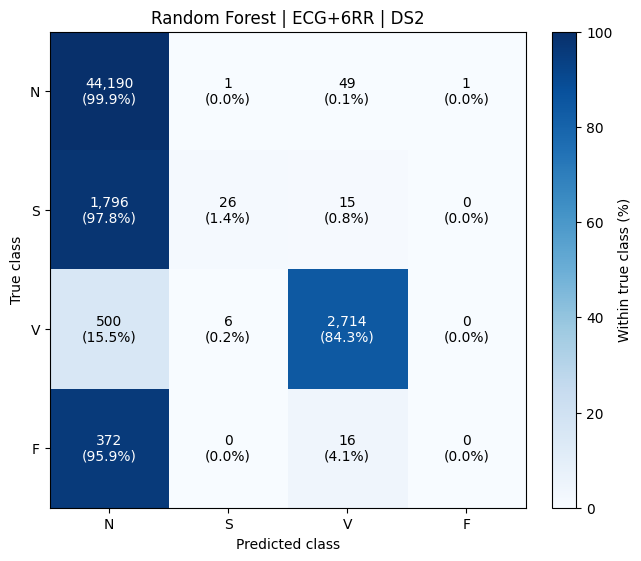

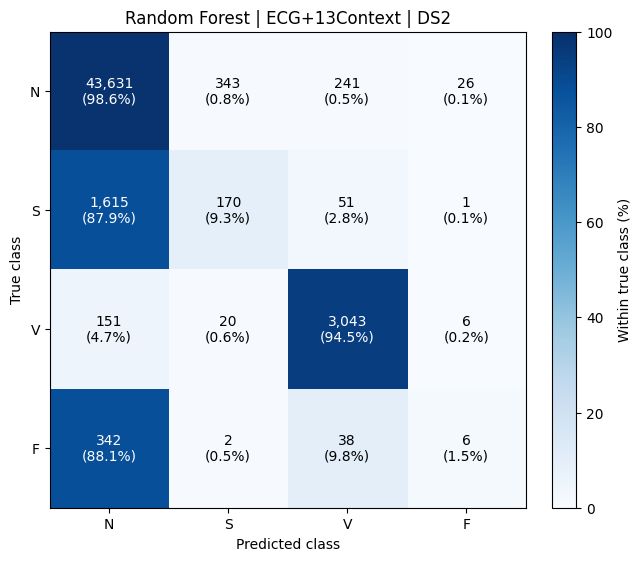

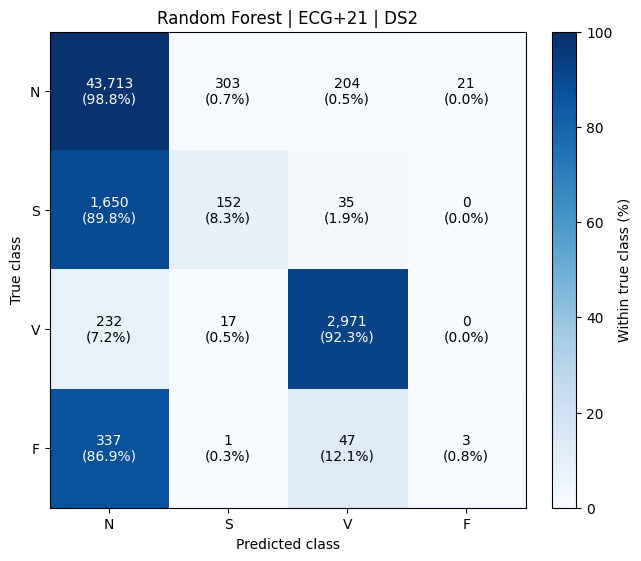

,model,stage,class,precision,recall,f1,support
0,Random Forest,ECG,N,0.943915,0.951041,0.947464,44241
1,Random Forest,ECG,S,0.046135,0.041916,0.043925,1837
2,Random Forest,ECG,V,0.805956,0.815217,0.810560,3220
3,Random Forest,ECG,F,0.000000,0.000000,0.000000,388
4,Random Forest,ECG+6RR,N,0.943062,0.998847,0.970153,44241
5,Random Forest,ECG+6RR,S,0.787879,0.014154,0.027807,1837
6,Random Forest,ECG+6RR,V,0.971367,0.842857,0.902561,3220
7,Random Forest,ECG+6RR,F,0.000000,0.000000,0.000000,388
8,Random Forest,ECG+13Context,N,0.953912,0.986212,0.969793,44241
9,Random Forest,ECG+13Context,S,0.317757,0.092542,0.143339,1837


Random Forest: four figures and results table saved.


In [14]:
# ============================================================
# RANDOM FOREST
# ONE CONFUSION-MATRIX FIGURE PER STAGE + RESULTS TABLE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, classification_report
from IPython.display import display

labels = ["N", "S", "V", "F"]
stages = ["ECG", "ECG+6RR", "ECG+13Context", "ECG+21"]

RESULTS_FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_METRICS_DIR.mkdir(parents=True, exist_ok=True)

rf_rows = []
rf_confusion_matrices = {}

for stage in stages:

    # Predict using the trained pipeline.
    predictions = rf_models[stage].predict(
        stage_data[stage]["X_ds2"]
    )

    cm = confusion_matrix(
        y_ds2, predictions, labels=labels
    )

    # Percentages are calculated within each true-class row.
    row_totals = cm.sum(axis=1, keepdims=True)

    percentages = np.divide(
        cm.astype(float),
        row_totals,
        out=np.zeros_like(cm, dtype=float),
        where=row_totals != 0,
    ) * 100

    # Create one separate figure for this stage.
    fig, ax = plt.subplots(
        figsize=(6.5, 5.5), constrained_layout=True
    )

    im = ax.imshow(
        percentages, cmap="Blues", vmin=0, vmax=100
    )

    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(
                j,
                i,
                f"{cm[i, j]:,}\n({percentages[i, j]:.1f}%)",
                ha="center",
                va="center",
                fontsize=10,
                color=(
                    "white" if percentages[i, j] > 50
                    else "black"
                ),
            )

    ax.set(
        xticks=range(len(labels)),
        yticks=range(len(labels)),
        xticklabels=labels,
        yticklabels=labels,
        xlabel="Predicted class",
        ylabel="True class",
        title=f"Random Forest | {stage} | DS2",
    )

    fig.colorbar(
        im, ax=ax, label="Within true class (%)"
    )

    safe_stage = stage.replace("+", "_plus_")
    filename = f"random_forest_{safe_stage}_ds2_confusion"

    for extension in ["png", "pdf"]:
        fig.savefig(
            RESULTS_FIGURES_DIR / f"{filename}.{extension}",
            dpi=300,
            bbox_inches="tight",
        )

    plt.show()
    plt.close(fig)

    # Store and save the confusion-matrix counts.
    cm_table = pd.DataFrame(
        cm,
        index=pd.Index(labels, name="True class"),
        columns=pd.Index(labels, name="Predicted class"),
    )

    rf_confusion_matrices[stage] = cm_table
    cm_table.to_csv(
        RESULTS_METRICS_DIR / f"{filename}.csv"
    )

    # Collect per-class results for this stage.
    report = classification_report(
        y_ds2,
        predictions,
        labels=labels,
        output_dict=True,
        zero_division=0,
    )

    for label in labels:
        rf_rows.append({
            "model": "Random Forest",
            "stage": stage,
            "class": label,
            "precision": report[label]["precision"],
            "recall": report[label]["recall"],
            "f1": report[label]["f1-score"],
            "support": int(report[label]["support"]),
        })

# Display one table containing all four stages.
rf_per_class_df = pd.DataFrame(rf_rows)

display(
    rf_per_class_df.style.format({
        "precision": "{:.6f}",
        "recall": "{:.6f}",
        "f1": "{:.6f}",
        "support": "{:d}",
    })
)

rf_per_class_df.to_csv(
    RESULTS_METRICS_DIR / "random_forest_four_stage_per_class_ds2.csv",
    index=False,
)

print("Random Forest: four figures and results table saved.")

### 4.5. XGBoost

Evaluate XGBoost across the same four feature stages and fixed DS1 folds.

Class-imbalance weighting is controlled by an exponent applied to
inverse-frequency class weights.

The same alpha search space is used for every feature stage.

In [14]:
# ============================================================
# XGBOOST CLASS AND WEIGHT SETUP
# ============================================================

CLASS_TO_INT = {
    "N": 0,
    "S": 1,
    "V": 2,
    "F": 3,
}


INT_TO_CLASS = {
    0: "N",
    1: "S",
    2: "V",
    3: "F",
}


y_ds1_encoded = np.asarray(
    [
        CLASS_TO_INT[
            label
        ]

        for label
        in y_ds1
    ],
    dtype=int
)


y_ds2_encoded = np.asarray(
    [
        CLASS_TO_INT[
            label
        ]

        for label
        in y_ds2
    ],
    dtype=int
)


K_CLASSES = len(
    CLASS_NAMES
)


ALPHA_GRID = [
    0.85,
    1.00,
    1.15,
    1.30,
]


print(
    "XGBoost feature stages:"
)

print(
    STAGE_NAMES
)


print(
    "\nAlpha grid:"
)

print(
    ALPHA_GRID
)

XGBoost feature stages:
['ECG', 'ECG+6RR', 'ECG+13Context', 'ECG+21']

Alpha grid:
[0.85, 1.0, 1.15, 1.3]


In [15]:
# ============================================================
# XGBOOST FOUR-STAGE FIXED-FOLD ALPHA SEARCH
# ============================================================

xgb_cv_rows = []


for stage_name in STAGE_NAMES:

    print(
        "\n"
        + "=" * 80
    )

    print(
        f"XGBOOST | {stage_name}"
    )

    print(
        "=" * 80
    )


    X_stage = (
        stage_data[
            stage_name
        ][
            "X_ds1"
        ]
    )


    for alpha in ALPHA_GRID:

        fold_macro_f1 = []

        fold_balanced_accuracy = []


        for (
            train_idx,
            val_idx

        ) in cv_folds:

            X_train_raw = (
                X_stage[
                    train_idx
                ]
            )


            X_val_raw = (
                X_stage[
                    val_idx
                ]
            )


            y_train_fold = (
                y_ds1_encoded[
                    train_idx
                ]
            )


            y_val_fold = (
                y_ds1_encoded[
                    val_idx
                ]
            )


            # =================================================
            # FOLD-SPECIFIC IMPUTATION
            # =================================================

            imputer = SimpleImputer(
                strategy="median"
            )


            X_train_fold = (
                imputer.fit_transform(
                    X_train_raw
                )
            )


            X_val_fold = (
                imputer.transform(
                    X_val_raw
                )
            )


            # =================================================
            # FOLD-SPECIFIC CLASS WEIGHTS
            # =================================================

            classes, counts = np.unique(
                y_train_fold,
                return_counts=True
            )


            N_train = len(
                y_train_fold
            )


            weight_map = {

                class_id:
                    (
                        N_train
                        /
                        (
                            K_CLASSES
                            * count
                        )
                    ) ** alpha

                for (
                    class_id,
                    count
                )

                in zip(
                    classes,
                    counts
                )
            }


            sample_weights = np.asarray(
                [
                    weight_map[
                        label
                    ]

                    for label
                    in y_train_fold
                ],
                dtype=float
            )


            # =================================================
            # MODEL
            # =================================================

            model = XGBClassifier(
                n_estimators=300,
                max_depth=5,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                min_child_weight=2,
                gamma=0.1,
                tree_method="hist",
                objective="multi:softprob",
                num_class=K_CLASSES,
                eval_metric="mlogloss",
                random_state=42,
                n_jobs=-1,
            )


            model.fit(
                X_train_fold,
                y_train_fold,
                sample_weight=
                    sample_weights
            )


            predictions = (
                model.predict(
                    X_val_fold
                )
            )


            predictions_labels = np.asarray(
                [
                    INT_TO_CLASS[
                        int(pred)
                    ]

                    for pred
                    in predictions
                ]
            )


            metrics = calculate_metrics(
                y_ds1[
                    val_idx
                ],

                predictions_labels
            )


            fold_macro_f1.append(
                metrics[
                    "macro_f1"
                ]
            )


            fold_balanced_accuracy.append(
                metrics[
                    "balanced_accuracy"
                ]
            )


        xgb_cv_rows.append(
            {
                "model":
                    "XGBoost",

                "stage":
                    stage_name,

                "alpha":
                    alpha,

                "mean_cv_macro_f1":
                    float(
                        np.mean(
                            fold_macro_f1
                        )
                    ),

                "std_cv_macro_f1":
                    float(
                        np.std(
                            fold_macro_f1
                        )
                    ),

                "mean_cv_balanced_accuracy":
                    float(
                        np.mean(
                            fold_balanced_accuracy
                        )
                    ),

                "std_cv_balanced_accuracy":
                    float(
                        np.std(
                            fold_balanced_accuracy
                        )
                    ),
            }
        )


xgb_cv_results_df = pd.DataFrame(
    xgb_cv_rows
)


# ============================================================
# SELECT BEST ALPHA FOR EACH STAGE
# ============================================================

best_xgb_rows = []


for stage_name in STAGE_NAMES:

    stage_results = (
        xgb_cv_results_df[
            xgb_cv_results_df[
                "stage"
            ]
            == stage_name
        ]
    )


    best_row = (
        select_best_cv_row(
            stage_results
        )
    )


    best_xgb_rows.append(
        best_row
    )


best_xgb_df = pd.DataFrame(
    best_xgb_rows
).reset_index(
    drop=True
)


display(
    best_xgb_df
)


xgb_cv_results_df.to_csv(
    RESULTS_METRICS_DIR
    / "xgboost_four_stage_cv.csv",
    index=False
)


XGBOOST | ECG

XGBOOST | ECG+6RR

XGBOOST | ECG+13Context

XGBOOST | ECG+21


,model,stage,alpha,mean_cv_macro_f1,std_cv_macro_f1,mean_cv_balanced_accuracy,std_cv_balanced_accuracy
0,XGBoost,ECG,0.85,0.377906,0.095717,0.474350,0.063023
1,XGBoost,ECG+6RR,1.15,0.430735,0.064232,0.521070,0.039604
2,XGBoost,ECG+13Context,0.85,0.467919,0.046547,0.536826,0.048485
3,XGBoost,ECG+21,0.85,0.453499,0.063954,0.536238,0.048832


In [16]:
# ============================================================
# FINAL XGBOOST MODELS AND DS2 EVALUATION
# ============================================================

xgb_models = {}

xgb_result_rows = []


for stage_name in STAGE_NAMES:

    best_row = (
        best_xgb_df[
            best_xgb_df[
                "stage"
            ]
            == stage_name
        ]
        .iloc[0]
    )


    best_alpha = float(
        best_row[
            "alpha"
        ]
    )


    X_ds1_stage_raw = (
        stage_data[
            stage_name
        ][
            "X_ds1"
        ]
    )


    X_ds2_stage_raw = (
        stage_data[
            stage_name
        ][
            "X_ds2"
        ]
    )


    # ========================================================
    # FINAL IMPUTER FIT ON ALL DS1
    # ========================================================

    final_imputer = SimpleImputer(
        strategy="median"
    )


    X_ds1_stage = (
        final_imputer.fit_transform(
            X_ds1_stage_raw
        )
    )


    X_ds2_stage = (
        final_imputer.transform(
            X_ds2_stage_raw
        )
    )


    # ========================================================
    # FINAL DS1 CLASS WEIGHTS
    # ========================================================

    classes, counts = np.unique(
        y_ds1_encoded,
        return_counts=True
    )


    weight_map = {

        class_id:
            (
                len(
                    y_ds1_encoded
                )
                /
                (
                    K_CLASSES
                    * count
                )
            ) ** best_alpha

        for (
            class_id,
            count
        )

        in zip(
            classes,
            counts
        )
    }


    sample_weights = np.asarray(
        [
            weight_map[
                label
            ]

            for label
            in y_ds1_encoded
        ],
        dtype=float
    )


    # ========================================================
    # FINAL MODEL
    # ========================================================

    model = XGBClassifier(
        n_estimators=300,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=2,
        gamma=0.1,
        tree_method="hist",
        objective="multi:softprob",
        num_class=K_CLASSES,
        eval_metric="mlogloss",
        random_state=42,
        n_jobs=-1,
    )


    model.fit(
        X_ds1_stage,
        y_ds1_encoded,
        sample_weight=
            sample_weights
    )


    predictions_encoded = (
        model.predict(
            X_ds2_stage
        )
    )


    predictions = np.asarray(
        [
            INT_TO_CLASS[
                int(pred)
            ]

            for pred
            in predictions_encoded
        ]
    )


    metrics = calculate_metrics(
        y_ds2,
        predictions
    )


    xgb_result_rows.append(
        {
            "model":
                "XGBoost",

            "stage":
                stage_name,

            "n_features":
                stage_data[
                    stage_name
                ][
                    "n_features"
                ],

            "selected_alpha":
                best_alpha,

            "cv_macro_f1_mean":
                best_row[
                    "mean_cv_macro_f1"
                ],

            "cv_macro_f1_std":
                best_row[
                    "std_cv_macro_f1"
                ],

            **metrics,
        }
    )


    xgb_models[
        stage_name
    ] = {
        "imputer":
            final_imputer,

        "model":
            model,
    }


xgb_results_df = pd.DataFrame(
    xgb_result_rows
)


display(
    xgb_results_df
)


xgb_results_df.to_csv(
    RESULTS_METRICS_DIR
    / "xgboost_four_stage_ds2.csv",
    index=False
)

,model,stage,n_features,selected_alpha,cv_macro_f1_mean,cv_macro_f1_std,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mcc
0,XGBoost,ECG,255,0.85,0.377906,0.095717,0.879423,0.476782,0.409575,0.476782,0.434968,0.883460,0.481234
1,XGBoost,ECG+6RR,261,1.15,0.430735,0.064232,0.879081,0.542651,0.515961,0.542651,0.515386,0.898642,0.519446
2,XGBoost,ECG+13Context,268,0.85,0.467919,0.046547,0.939198,0.559930,0.590686,0.559930,0.569373,0.931939,0.678663
3,XGBoost,ECG+21,276,0.85,0.453499,0.063954,0.941050,0.564611,0.608836,0.564611,0.579913,0.933554,0.686163


## Confusion matrix xgboost

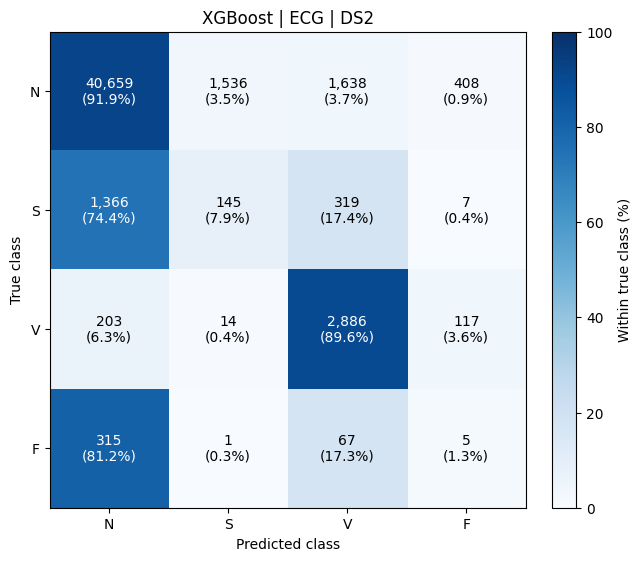

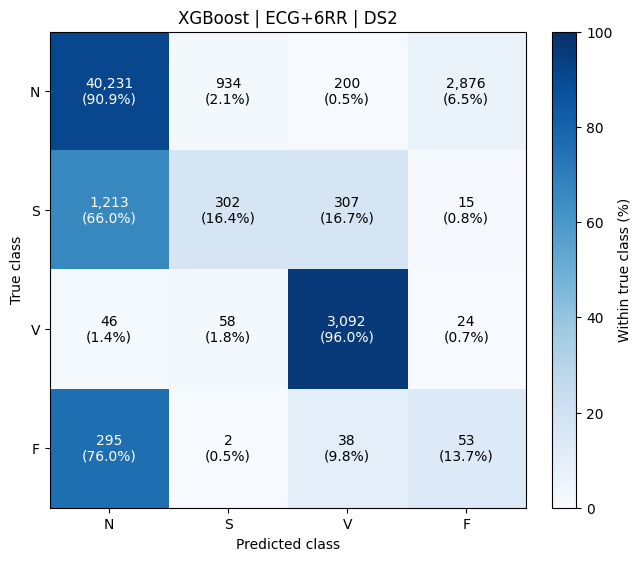

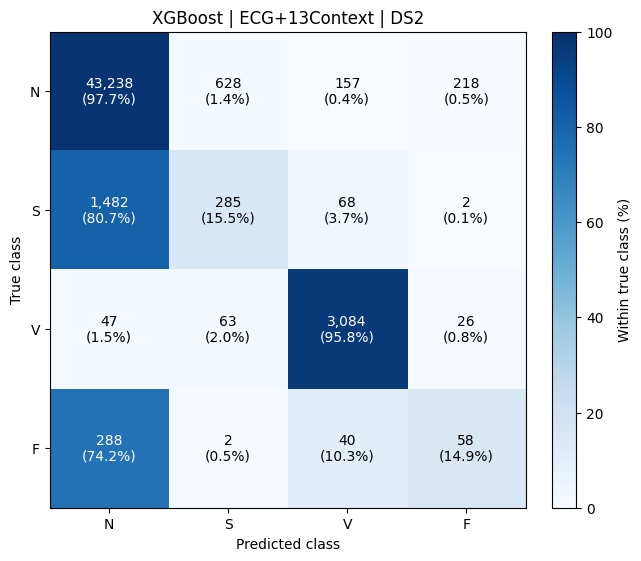

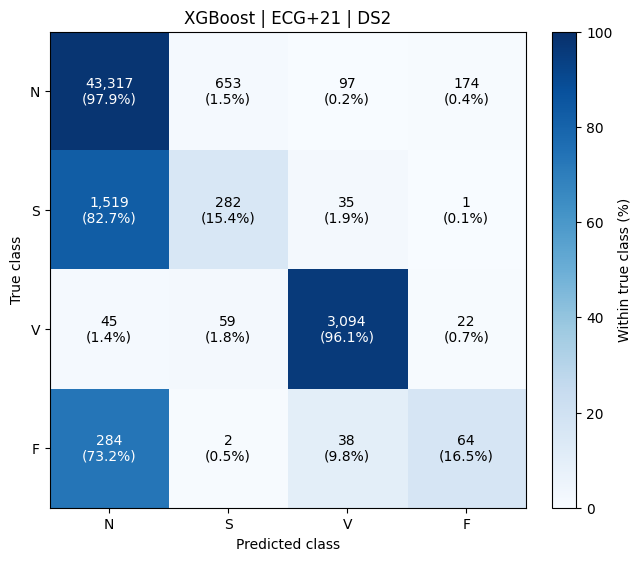

,model,stage,class,precision,recall,f1,support
0,XGBoost,ECG,N,0.955715,0.919034,0.937016,44241
1,XGBoost,ECG,S,0.085495,0.078933,0.082083,1837
2,XGBoost,ECG,V,0.587780,0.896273,0.709963,3220
3,XGBoost,ECG,F,0.009311,0.012887,0.010811,388
4,XGBoost,ECG+6RR,N,0.962810,0.909360,0.935322,44241
5,XGBoost,ECG+6RR,S,0.233025,0.164398,0.192786,1837
6,XGBoost,ECG+6RR,V,0.850151,0.960248,0.901852,3220
7,XGBoost,ECG+6RR,F,0.017857,0.136598,0.031585,388
8,XGBoost,ECG+13Context,N,0.959672,0.977329,0.968420,44241
9,XGBoost,ECG+13Context,S,0.291411,0.155144,0.202487,1837


XGBoost: four figures and results table saved.


In [15]:
# ============================================================
# XGBOOST
# ONE CONFUSION-MATRIX FIGURE PER STAGE + RESULTS TABLE
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import confusion_matrix, classification_report
from IPython.display import display

labels = ["N", "S", "V", "F"]
stages = ["ECG", "ECG+6RR", "ECG+13Context", "ECG+21"]

RESULTS_FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_METRICS_DIR.mkdir(parents=True, exist_ok=True)

xgb_rows = []
xgb_confusion_matrices = {}

for stage in stages:

    artifact = xgb_models[stage]

    # Apply the imputer previously fitted on DS1.
    X_test = artifact["imputer"].transform(
        stage_data[stage]["X_ds2"]
    )

    encoded_predictions = artifact["model"].predict(X_test)

    # Convert numeric predictions back to N, S, V, and F.
    if "int_to_class" in artifact:
        label_mapping = artifact["int_to_class"]
    else:
        label_mapping = INT_TO_CLASS

    predictions = np.asarray([
        label_mapping[int(label)]
        for label in encoded_predictions
    ])

    cm = confusion_matrix(
        y_ds2, predictions, labels=labels
    )

    # Percentages are calculated within each true-class row.
    row_totals = cm.sum(axis=1, keepdims=True)

    percentages = np.divide(
        cm.astype(float),
        row_totals,
        out=np.zeros_like(cm, dtype=float),
        where=row_totals != 0,
    ) * 100

    # Create one separate figure for this stage.
    fig, ax = plt.subplots(
        figsize=(6.5, 5.5), constrained_layout=True
    )

    im = ax.imshow(
        percentages, cmap="Blues", vmin=0, vmax=100
    )

    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(
                j,
                i,
                f"{cm[i, j]:,}\n({percentages[i, j]:.1f}%)",
                ha="center",
                va="center",
                fontsize=10,
                color=(
                    "white" if percentages[i, j] > 50
                    else "black"
                ),
            )

    ax.set(
        xticks=range(len(labels)),
        yticks=range(len(labels)),
        xticklabels=labels,
        yticklabels=labels,
        xlabel="Predicted class",
        ylabel="True class",
        title=f"XGBoost | {stage} | DS2",
    )

    fig.colorbar(
        im, ax=ax, label="Within true class (%)"
    )

    safe_stage = stage.replace("+", "_plus_")
    filename = f"xgboost_{safe_stage}_ds2_confusion"

    for extension in ["png", "pdf"]:
        fig.savefig(
            RESULTS_FIGURES_DIR / f"{filename}.{extension}",
            dpi=300,
            bbox_inches="tight",
        )

    plt.show()
    plt.close(fig)

    # Store and save the confusion-matrix counts.
    cm_table = pd.DataFrame(
        cm,
        index=pd.Index(labels, name="True class"),
        columns=pd.Index(labels, name="Predicted class"),
    )

    xgb_confusion_matrices[stage] = cm_table
    cm_table.to_csv(
        RESULTS_METRICS_DIR / f"{filename}.csv"
    )

    # Collect per-class results for this stage.
    report = classification_report(
        y_ds2,
        predictions,
        labels=labels,
        output_dict=True,
        zero_division=0,
    )

    for label in labels:
        xgb_rows.append({
            "model": "XGBoost",
            "stage": stage,
            "class": label,
            "precision": report[label]["precision"],
            "recall": report[label]["recall"],
            "f1": report[label]["f1-score"],
            "support": int(report[label]["support"]),
        })

# Display one table containing all four stages.
xgb_per_class_df = pd.DataFrame(xgb_rows)

display(
    xgb_per_class_df.style.format({
        "precision": "{:.6f}",
        "recall": "{:.6f}",
        "f1": "{:.6f}",
        "support": "{:d}",
    })
)

xgb_per_class_df.to_csv(
    RESULTS_METRICS_DIR / "xgboost_four_stage_per_class_ds2.csv",
    index=False,
)

print("XGBoost: four figures and results table saved.")

### 4.6. Compare Models Across All Four Feature Stages

Combine the final Logistic Regression, Random Forest, and XGBoost results
into one 12-condition comparison table.

The primary comparison metric is Macro-F1.

In [17]:
# ============================================================
# COMBINE ALL CONVENTIONAL ML RESULTS
# ============================================================

results_df = pd.concat(
    [
        logistic_results_df,
        rf_results_df,
        xgb_results_df,
    ],
    ignore_index=True
)


# ============================================================
# DEFINE ORDER
# ============================================================

stage_order = {
    "ECG": 1,
    "ECG+6RR": 2,
    "ECG+13Context": 3,
    "ECG+21": 4,
}


model_order = {
    "Logistic Regression": 1,
    "Random Forest": 2,
    "XGBoost": 3,
}


results_df[
    "stage_order"
] = (
    results_df[
        "stage"
    ]
    .map(
        stage_order
    )
)


results_df[
    "model_order"
] = (
    results_df[
        "model"
    ]
    .map(
        model_order
    )
)


# ============================================================
# SORT BY MODEL AND FEATURE STAGE
# ============================================================

results_df = (
    results_df
    .sort_values(
        by=[
            "model_order",
            "stage_order",
        ]
    )
    .drop(
        columns=[
            "model_order",
            "stage_order",
        ]
    )
    .reset_index(
        drop=True
    )
)


# ============================================================
# ROUND DISPLAY METRICS
# ============================================================

metric_columns = [
    "cv_macro_f1_mean",
    "cv_macro_f1_std",
    "accuracy",
    "balanced_accuracy",
    "macro_precision",
    "macro_recall",
    "macro_f1",
    "weighted_f1",
    "mcc",
]


for column in metric_columns:

    if column in results_df.columns:

        results_df[
            column
        ] = (
            results_df[
                column
            ]
            .round(
                4
            )
        )


# ============================================================
# DISPLAY FINAL TABLE
# ============================================================

print("=" * 100)

print(
    "CONVENTIONAL ML FOUR-STAGE COMPARISON"
)

print("=" * 100)


display(
    results_df
)


# ============================================================
# SAVE FINAL TABLE
# ============================================================

comparison_path = (
    RESULTS_METRICS_DIR
    / "conventional_ml_four_stage_comparison.csv"
)


results_df.to_csv(
    comparison_path,
    index=False
)


print(
    "\nSaved to:"
)

print(
    comparison_path
)

CONVENTIONAL ML FOUR-STAGE COMPARISON


,model,stage,n_features,selected_C,cv_macro_f1_mean,cv_macro_f1_std,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,mcc,selected_max_depth,selected_min_samples_leaf,selected_alpha
0,Logistic Regression,ECG,255,0.01,0.2769,0.0887,0.5968,0.4436,0.3311,0.4436,0.3152,0.6927,0.1663,NaN,NaN,NaN
1,Logistic Regression,ECG+6RR,261,0.01,0.3170,0.0872,0.7011,0.5676,0.4057,0.5676,0.4064,0.7788,0.3081,NaN,NaN,NaN
2,Logistic Regression,ECG+13Context,268,1.00,0.3806,0.0608,0.7674,0.6021,0.4329,0.6021,0.4503,0.8218,0.3644,NaN,NaN,NaN
3,Logistic Regression,ECG+21,276,0.10,0.4022,0.0814,0.8362,0.5723,0.4752,0.5723,0.4916,0.8690,0.4366,NaN,NaN,NaN
4,Random Forest,ECG,255,NaN,0.3796,0.0618,0.9012,0.4520,0.4490,0.4520,0.4505,0.8978,0.4954,10.0,1.0,NaN
5,Random Forest,ECG+6RR,261,NaN,0.4181,0.0856,0.9445,0.4640,0.6756,0.4640,0.4751,0.9234,0.6873,NaN,1.0,NaN
6,Random Forest,ECG+13Context,268,NaN,0.4338,0.0502,0.9429,0.5098,0.5819,0.5098,0.5161,0.9289,0.6861,10.0,2.0,NaN
7,Random Forest,ECG+21,276,NaN,0.4436,0.0556,0.9427,0.5003,0.5776,0.5003,0.5083,0.9277,0.6819,10.0,2.0,NaN
8,XGBoost,ECG,255,NaN,0.3779,0.0957,0.8794,0.4768,0.4096,0.4768,0.4350,0.8835,0.4812,NaN,NaN,0.85
9,XGBoost,ECG+6RR,261,NaN,0.4307,0.0642,0.8791,0.5427,0.5160,0.5427,0.5154,0.8986,0.5194,NaN,NaN,1.15



Saved to:
/Users/janusaban/Documents/ML_research/05_ecg-ml/results/metrics/conventional_ml_four_stage_comparison.csv


### 4.7. Save Model Artifacts

Save the fitted final models and the complete four-stage comparison.

The fixed cross-validation fold file remains the fold definition generated
by Notebook 02.

In [18]:
# ============================================================
# SAVE FINAL FOUR-STAGE MODEL ARTIFACTS
# ============================================================

ARTIFACT_DIR = (
    MODELS_DIR
    / "conventional_four_stage"
)


ARTIFACT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# SAVE LOGISTIC REGRESSION MODELS
# ============================================================

for (
    stage_name,
    model

) in logistic_models.items():

    safe_stage_name = (
        stage_name
        .replace(
            "+",
            "_plus_"
        )
    )


    path = (
        ARTIFACT_DIR
        / (
            f"logistic_"
            f"{safe_stage_name}.joblib"
        )
    )


    joblib.dump(
        {
            "model":
                model,

            "stage":
                stage_name,

            "fold_file":
                str(
                    required_files[
                        "Fixed CV folds"
                    ]
                ),

            "class_names":
                CLASS_NAMES,
        },

        path
    )


# ============================================================
# SAVE RANDOM FOREST MODELS
# ============================================================

for (
    stage_name,
    model

) in rf_models.items():

    safe_stage_name = (
        stage_name
        .replace(
            "+",
            "_plus_"
        )
    )


    path = (
        ARTIFACT_DIR
        / (
            f"random_forest_"
            f"{safe_stage_name}.joblib"
        )
    )


    joblib.dump(
        {
            "model":
                model,

            "stage":
                stage_name,

            "fold_file":
                str(
                    required_files[
                        "Fixed CV folds"
                    ]
                ),

            "class_names":
                CLASS_NAMES,
        },

        path
    )


# ============================================================
# SAVE XGBOOST MODELS
# ============================================================

for (
    stage_name,
    artifact

) in xgb_models.items():

    safe_stage_name = (
        stage_name
        .replace(
            "+",
            "_plus_"
        )
    )


    path = (
        ARTIFACT_DIR
        / (
            f"xgboost_"
            f"{safe_stage_name}.joblib"
        )
    )


    joblib.dump(
        {
            "imputer":
                artifact[
                    "imputer"
                ],

            "model":
                artifact[
                    "model"
                ],

            "stage":
                stage_name,

            "fold_file":
                str(
                    required_files[
                        "Fixed CV folds"
                    ]
                ),

            "class_names":
                CLASS_NAMES,

            "class_to_int":
                CLASS_TO_INT,

            "int_to_class":
                INT_TO_CLASS,
        },

        path
    )


# ============================================================
# SAVE COMPLETE COMPARISON TABLE AGAIN
# ============================================================

results_df.to_csv(
    RESULTS_METRICS_DIR
    / "conventional_ml_four_stage_comparison.csv",
    index=False
)


# ============================================================
# COMPLETION SUMMARY
# ============================================================

print("=" * 80)

print(
    "NOTEBOOK 04 COMPLETED SUCCESSFULLY"
)

print("=" * 80)


print(
    "\nModels evaluated:"
)

print(
    "1. Logistic Regression"
)

print(
    "2. Random Forest"
)

print(
    "3. XGBoost"
)


print(
    "\nFeature stages:"
)

for stage_name in STAGE_NAMES:

    print(
        f"- {stage_name}"
    )


print(
    "\nTotal experimental conditions:"
)

print(
    len(STAGE_NAMES)
    * 3
)


print(
    "\nAll conditions used the same fixed DS1 folds:"
)

print(
    required_files[
        "Fixed CV folds"
    ]
)


print("=" * 80)

NOTEBOOK 04 COMPLETED SUCCESSFULLY

Models evaluated:
1. Logistic Regression
2. Random Forest
3. XGBoost

Feature stages:
- ECG
- ECG+6RR
- ECG+13Context
- ECG+21

Total experimental conditions:
12

All conditions used the same fixed DS1 folds:
/Users/janusaban/Documents/ML_research/05_ecg-ml/data/processed/ds1_cv_record_folds.csv
